# 10-5. 데이터의 계절성 확인 (X3_l1)

분기 데이터(2011Q1~2025Q4, 60개)의 수준 `y`와 1차 차분 `Δy`에 4분기 주기의 계절성이 있는지 확인한다. 방법은 ACF(시차 4, 8), 분기별 평균 비교, STL 계절 강도, 계절 더미 F검정이다.

`X3_l1`은 4분기 합이라 분기별 패턴이 상쇄되므로(`Δy`도 '새 분기 - 4분기 전 분기') 계절성이 없을 것으로 예상한다(변수 이름에서 추론한 가정). 표본이 작아 유의하지 않아도 '없다'는 증명은 아니다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.seasonal import STL
import statsmodels.formula.api as smf
import statsmodels.api as sm
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
df = raw[["quarter", "X3_l1"]].dropna().reset_index(drop=True)
df["qtr"] = df["quarter"].str[-2:]                         # Q1~Q4
df["y"] = df["X3_l1"].astype(float)
df["dy"] = df["y"].diff()
print(f"{len(df)}개 분기: {df['quarter'].iloc[0]} ~ {df['quarter'].iloc[-1]}  (Δy는 {df['dy'].notna().sum()}개)")
print(df["qtr"].value_counts().sort_index().to_dict())

60개 분기: 2011Q1 ~ 2025Q4  (Δy는 59개)
{'Q1': 15, 'Q2': 15, 'Q3': 15, 'Q4': 15}


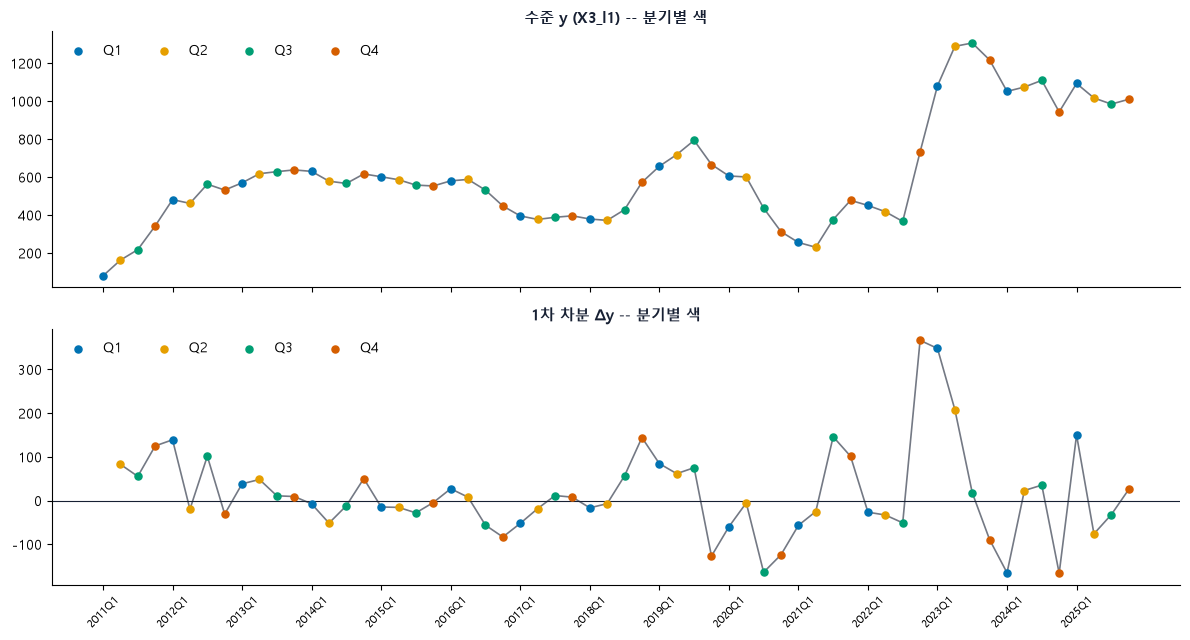

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
cm = {"Q1": "#0072B2", "Q2": "#E69F00", "Q3": "#009E73", "Q4": "#D55E00"}
x = np.arange(len(df))
for ax, col, t in [(axes[0], "y", "수준 y (X3_l1)"), (axes[1], "dy", "1차 차분 Δy")]:
    ax.plot(x, df[col], color="#172033", linewidth=1.2, alpha=0.6)
    for q, c in cm.items():
        m = df["qtr"] == q
        ax.scatter(x[m], df.loc[m, col], color=c, s=26, label=q, zorder=3)
    if col == "dy":
        ax.axhline(0, color="#172033", linewidth=0.8)
    ax.set_title(t + " -- 분기별 색", fontsize=11, fontweight="bold", color="#172033")
    ax.legend(ncol=4, frameon=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
axes[1].set_xticks(x[::4])
axes[1].set_xticklabels(df["quarter"].values[::4], fontsize=8, rotation=45)
fig.tight_layout()
plt.show()

## 1. ACF -- 시차 4, 8

판단은 `Δy` 기준이다(`y`는 비정상이라 시차 4가 크게 보이는 것이 정상).

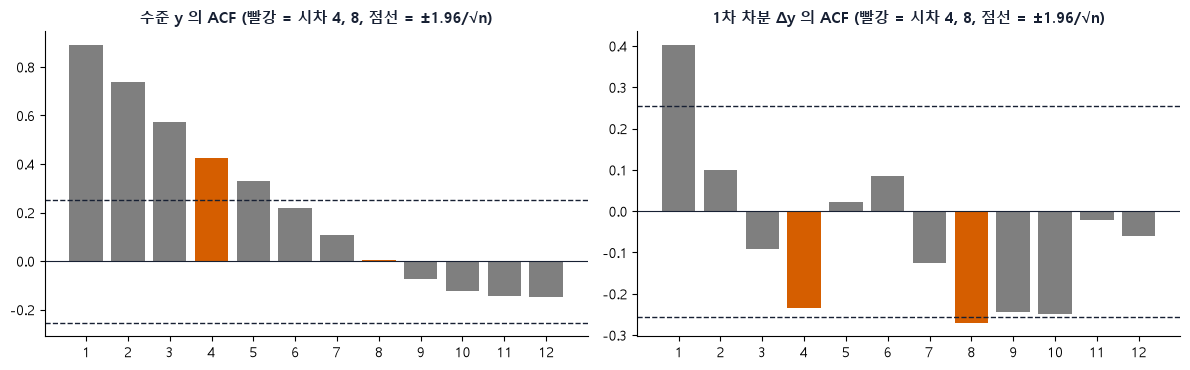

,lag 1,lag 2,lag 3,lag 4,lag 5,lag 6,lag 7,lag 8
수준 y (밴드 ±0.25),0.890,0.737,0.573,0.425,0.332,0.218,0.106,0.006
1차 차분 Δy (밴드 ±0.26),0.402,0.101,-0.091,-0.234,0.021,0.086,-0.127,-0.270


In [3]:
NL = 12
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
tabs = []
for ax, col, t in [(axes[0], "y", "수준 y"), (axes[1], "dy", "1차 차분 Δy")]:
    v = df[col].dropna().values
    a = acf(v, nlags=NL, fft=False)
    band = 1.96 / np.sqrt(len(v))
    ax.bar(range(1, NL + 1), a[1:], color=["#D55E00" if k in (4, 8) else "#7F7F7F" for k in range(1, NL + 1)])
    ax.axhline(band, color="#172033", linestyle="--", linewidth=1)
    ax.axhline(-band, color="#172033", linestyle="--", linewidth=1)
    ax.axhline(0, color="#172033", linewidth=0.8)
    ax.set_title(f"{t} 의 ACF (빨강 = 시차 4, 8, 점선 = ±1.96/√n)", fontsize=10.5, fontweight="bold", color="#172033")
    ax.set_xticks(range(1, NL + 1))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    tabs.append(pd.Series({f"lag {k}": a[k] for k in (1, 2, 3, 4, 5, 6, 7, 8)}, name=f"{t} (밴드 ±{band:.2f})"))
fig.tight_layout()
plt.show()
display(pd.DataFrame(tabs).round(3))

## 2. 분기별 평균 비교 (Δy)

,count,mean,median,std
qtr,,,,
Q1,14,27.5,-11.3,123.9
Q2,15,11.8,-7.2,68.6
Q3,15,11.0,11.3,74.7
Q4,15,13.5,7.6,135.3


Kruskal-Wallis: H = 0.24, p = 0.970
ANOVA(일원): F = 0.08, p = 0.971


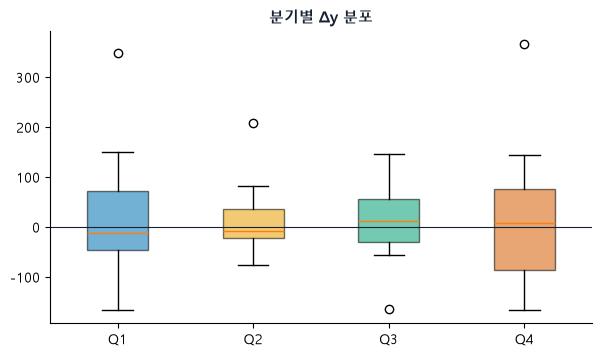

In [4]:
d = df.dropna(subset=["dy"])
groups = [d.loc[d["qtr"] == q, "dy"].values for q in ["Q1", "Q2", "Q3", "Q4"]]
summ = d.groupby("qtr")["dy"].agg(["count", "mean", "median", "std"])
display(summ.round(1))
kw = stats.kruskal(*groups)
an = stats.f_oneway(*groups)
print(f"Kruskal-Wallis: H = {kw.statistic:.2f}, p = {kw.pvalue:.3f}")
print(f"ANOVA(일원): F = {an.statistic:.2f}, p = {an.pvalue:.3f}")
fig, ax = plt.subplots(figsize=(7, 3.8))
bp = ax.boxplot(groups, patch_artist=True)
ax.set_xticklabels(["Q1", "Q2", "Q3", "Q4"])
for patch, c in zip(bp["boxes"], cm.values()):
    patch.set_facecolor(c)
    patch.set_alpha(0.55)
ax.axhline(0, color="#172033", linewidth=0.8)
ax.set_title("분기별 Δy 분포", fontsize=11, fontweight="bold", color="#172033")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

## 3. STL 분해

계절 강도 `Fs = max(0, 1 - Var(잔차) / Var(계절 + 잔차))`, 0이면 계절성 없음.

계절 강도 Fs -- 수준 y: 0.000, 차분 Δy: 0.000


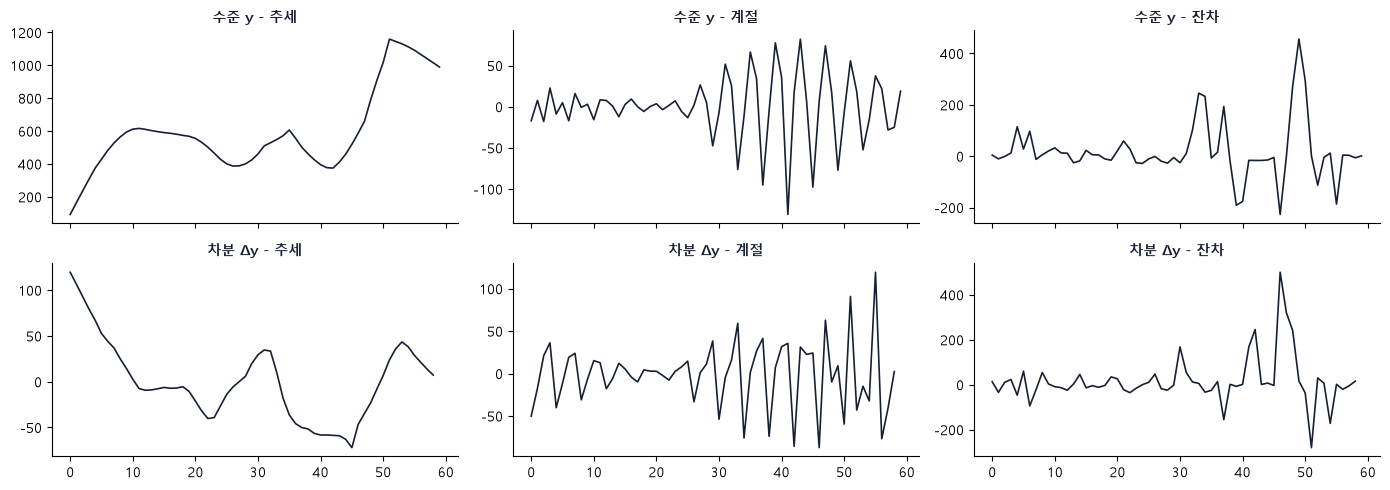

계절 성분의 진폭(최대-최소) -- 수준 y: 213.1, 차분 Δy: 206.7  (y 표준편차 285.0, Δy 표준편차 101.9)


In [5]:
def seasonal_strength(series):
    r = STL(series, period=4, robust=True).fit()
    return r, max(0.0, 1 - np.var(r.resid) / np.var(r.seasonal + r.resid))

res_y, fs_y = seasonal_strength(df["y"].values)
res_d, fs_d = seasonal_strength(df["dy"].dropna().values)
print(f"계절 강도 Fs -- 수준 y: {fs_y:.3f}, 차분 Δy: {fs_d:.3f}")
fig, axes = plt.subplots(2, 3, figsize=(14, 5), sharex="col")
for row, (r, t) in enumerate([(res_y, "수준 y"), (res_d, "차분 Δy")]):
    for col, (comp, nm) in enumerate([(r.trend, "추세"), (r.seasonal, "계절"), (r.resid, "잔차")]):
        axes[row, col].plot(comp, color="#172033", linewidth=1.2)
        axes[row, col].set_title(f"{t} - {nm}", fontsize=10, fontweight="bold", color="#172033")
        axes[row, col].spines["top"].set_visible(False)
        axes[row, col].spines["right"].set_visible(False)
fig.tight_layout()
plt.show()
print("계절 성분의 진폭(최대-최소) -- 수준 y: %.1f, 차분 Δy: %.1f  (y 표준편차 %.1f, Δy 표준편차 %.1f)" % (
    np.ptp(res_y.seasonal), np.ptp(res_d.seasonal), df["y"].std(), df["dy"].std()))

## 4. 계절 더미 회귀 (F검정)

In [6]:
d = df.copy()
d["t"] = np.arange(len(d))
m_dy = smf.ols("dy ~ C(qtr)", data=d.dropna(subset=["dy"])).fit()
m_y = smf.ols("y ~ t + C(qtr)", data=d).fit()
m_y0 = smf.ols("y ~ t", data=d).fit()
f_y = m_y.compare_f_test(m_y0)
rows = [
    {"대상": "Δy ~ 분기 더미", "F": m_dy.fvalue, "p-value": m_dy.f_pvalue, "R²": m_dy.rsquared},
    {"대상": "y ~ 추세 + 분기 더미 (분기 효과만 검정)", "F": f_y[0], "p-value": f_y[1], "R²": m_y.rsquared - m_y0.rsquared},
]
display(pd.DataFrame(rows).set_index("대상").round(3))
print("R²는 분기 더미가 추가로 설명하는 분산 비율")

,F,p-value,R²
대상,,,
Δy ~ 분기 더미,0.079,0.971,0.004
y ~ 추세 + 분기 더미 (분기 효과만 검정),0.002,1.000,0.000


R²는 분기 더미가 추가로 설명하는 분산 비율


## 5. 요약

In [7]:
a_dy = acf(df["dy"].dropna().values, nlags=8, fft=False)
band = 1.96 / np.sqrt(df["dy"].notna().sum())
summary = pd.DataFrame([
    {"방법": "ACF (Δy) 시차 4, 8", "결과": f"{a_dy[4]:.3f}, {a_dy[8]:.3f} (밴드 ±{band:.2f})", "계절성": "시차 4, 8 모두 밴드 안" if max(abs(a_dy[4]), abs(a_dy[8])) < band else "밴드 밖 있음"},
    {"방법": "분기별 평균 비교 (Δy)", "결과": f"Kruskal p = {kw.pvalue:.3f}, ANOVA p = {an.pvalue:.3f}", "계절성": "유의하지 않음" if min(kw.pvalue, an.pvalue) >= 0.05 else "유의함"},
    {"방법": "STL 계절 강도", "결과": f"y {fs_y:.3f}, Δy {fs_d:.3f}", "계절성": "-"},
    {"방법": "계절 더미 F검정", "결과": f"Δy p = {m_dy.f_pvalue:.3f}, y(추세 포함) p = {f_y[1]:.3f}", "계절성": "유의하지 않음" if min(m_dy.f_pvalue, f_y[1]) >= 0.05 else "유의함"},
]).set_index("방법")
display(summary)

,결과,계절성
방법,,
"ACF (Δy) 시차 4, 8","-0.234, -0.270 (밴드 ±0.26)",밴드 밖 있음
분기별 평균 비교 (Δy),"Kruskal p = 0.970, ANOVA p = 0.971",유의하지 않음
STL 계절 강도,"y 0.000, Δy 0.000",-
계절 더미 F검정,"Δy p = 0.971, y(추세 포함) p = 1.000",유의하지 않음


## 6. 결론

**4분기 주기의 뚜렷한 계절성은 확인되지 않았다.** 다만 ACF 시차 8이 밴드를 근소하게 벗어나 '없다'고 단정하지는 않는다.

| 방법 | 결과 | 판단 |
|---|---|---|
| ACF (Δy) 시차 4, 8 | -0.234, -0.270 (밴드 ±0.26) | 시차 8만 근소하게 밖 |
| 분기별 평균 비교 (Δy) | Kruskal p = 0.970, ANOVA p = 0.971 | 차이 없음 |
| STL 계절 강도 | y 0.000, Δy 0.000 | 계절성 없음 |
| 계절 더미 F검정 | Δy p = 0.971, y p = 1.000 | 분기 효과 없음 |

- 시차 8은 12개 중 하나가 근소하게 벗어난 정도이고 다른 방법에는 신호가 없다.
- STL 진폭(약 210)은 노이즈를 뽑은 것이라(강도 0) 신뢰하지 않는다.
- 이전의 '계절차분이 나쁘다'는 결과와 같은 방향이다.
- 한계: 표본이 작아(Δy 59개) 검정력이 낮고, 분기별 원자료의 계절성은 알 수 없다.